# Clase 4 — Trama LoRa con payload de 10 bytes: hola mundo

Copia de la clase 4 con el mensaje ASCII **`hola mundo`**: 10 caracteres contando el espacio, 10 símbolos de 8 bits y 80 bits de payload. Conservamos los 8 upchirps y los 2¼ downchirps, detectamos el inicio, recuperamos el mensaje completo y medimos PER con `paquetes_por_snr` ensayos por SNR y canal.

Usamos el modelo discreto de las ecuaciones (2) y (3) de Vangelista, *Frequency Shift Chirp Modulation: The LoRa Modulation*. La función de correlación paso a paso se conserva; la variante rápida se usa únicamente para las repeticiones de PER.


In [20]:
# Cargamos las herramientas de simulación y las funciones de las clases anteriores.
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

raiz = Path.cwd()
if not (raiz / 'src').exists():
    raiz = raiz.parent
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.lora_chirp import (
    agregar_ruido_awgn, demodular_simbolo, modular_simbolo,
    parametros_ruido_desde_snr, validar_simbolos,
)

## 1. Parámetros y mensaje ASCII

Usamos $SF=8$, $N=2^{SF}=256$ y $B=125$ kHz, con muestreo a $B$. Cada símbolo dura $T_s=N/B=2{,}048$ ms. Cada carácter de `hola mundo`, incluido el espacio, ocupa un byte y se transmite como un chirp de `N` muestras: **10 símbolos, 80 bits y 2560 muestras de payload**.

El receptor conoce la longitud de 10 bytes para recortar el mensaje; esta trama didáctica todavía no transmite un encabezado de longitud.


In [21]:
# Un byte por carácter; mantenemos SF=8, aunque el mensaje tenga 10 símbolos.
B = 125_000
mensaje = 'hola mundo'
payload_transmitido = mensaje.encode('ascii')
cantidad_caracteres = len(payload_transmitido)
assert cantidad_caracteres == 10, 'En esta copia usamos un mensaje ASCII de 10 bytes'
valores_ascii = list(payload_transmitido)
bits_payload = [f'{valor:08b}' for valor in valores_ascii]
# El helper admite por defecto hasta 5 símbolos; aquí habilitamos los 10 solicitados.
SF = validar_simbolos(bits_payload, max_simbolos=10)
N = 2**SF
Ts = N / B
k = np.arange(N)
longitud_payload = cantidad_caracteres * N

print(f'Mensaje: {mensaje!r} | {cantidad_caracteres} bytes | {8*cantidad_caracteres} bits')
print(f'SF={SF} | chirp={N} muestras | Ts={Ts*1e3:.3f} ms')
print('Posición  Carácter  ASCII  Bits')
for posicion, (caracter, valor, bits) in enumerate(zip(mensaje, valores_ascii, bits_payload)):
    print(f'{posicion:8d}  {caracter!r:7}  {valor:5d}  {bits}')


Mensaje: 'hola mundo' | 10 bytes | 80 bits
SF=8 | chirp=256 muestras | Ts=2.048 ms
Posición  Carácter  ASCII  Bits
       0  'h'        104  01101000
       1  'o'        111  01101111
       2  'l'        108  01101100
       3  'a'         97  01100001
       4  ' '         32  00100000
       5  'm'        109  01101101
       6  'u'        117  01110101
       7  'n'        110  01101110
       8  'd'        100  01100100
       9  'o'        111  01101111


## 2. Construcción y visualización de la trama

La trama contiene **8 upchirps + 2¼ downchirps + 10 símbolos de payload**. Cada byte selecciona su propio chirp, sin modificar la cantidad de muestras por símbolo:

$$c_s[k]=\frac{1}{\sqrt{N}}e^{j2\pi[((s+k)\bmod N)k/N]},\qquad k=0,\ldots,N-1.$$

El upchirp usa $s=0$ y el downchirp es su conjugado. Concatenamos los 10 chirps del mensaje en el orden de sus caracteres. Este modelo de clase no incluye palabra de sincronización, codificación, encabezado ni CRC.


In [22]:
# Los helpers modulan los 10 bytes; el preámbulo y los downchirps se conservan.
upchirp_cero = np.exp(1j * 2 * np.pi * k**2 / N) / np.sqrt(N)
downchirp_cero = np.conj(upchirp_cero)
simbolos_payload = np.array([modular_simbolo(valor, k, N) for valor in valores_ascii])
payload_modulado = simbolos_payload.ravel()
preambulo = np.tile(upchirp_cero, 8)
sincronizacion = np.concatenate((downchirp_cero, downchirp_cero, downchirp_cero[:N // 4]))
trama_transmitida = np.concatenate((preambulo, sincronizacion, payload_modulado))
recibida_ideal = trama_transmitida.copy()
limites = np.array([0, 8*N, 10*N, 10*N + N//4, 10*N + N//4 + longitud_payload])
assert simbolos_payload.shape == (cantidad_caracteres, N)
assert len(recibida_ideal) == limites[-1] == 5184
assert np.isclose(np.vdot(upchirp_cero, upchirp_cero).real, 1)
print(f'Trama: {len(preambulo)} de preámbulo + {len(sincronizacion)} de downchirps'
      f' + {longitud_payload} de payload = {len(recibida_ideal)} muestras'
      f' ({len(recibida_ideal)/B*1e3:.3f} ms)')


Trama: 2048 de preámbulo + 576 de downchirps + 2560 de payload = 5184 muestras (41.472 ms)


Graficamos la parte real de la señal y el índice modular de la rampa. Los colores separan preámbulo, downchirps y payload; las etiquetas del payload muestran cada carácter, incluido `' '` para el espacio.


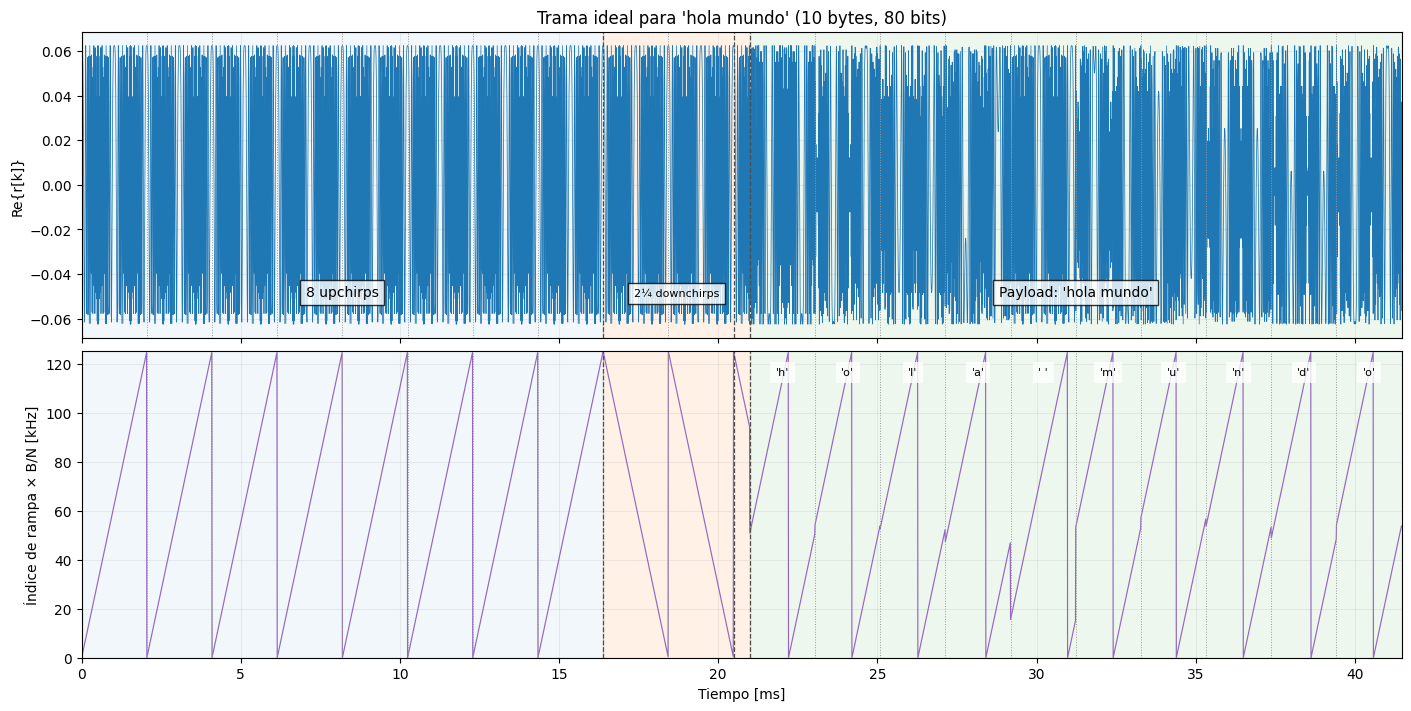

In [23]:
# Unimos las rampas de los 10 caracteres en el mismo orden que sus chirps.
rampa_up = k * B / N
rampa_down = B - rampa_up
rampa_payload = np.concatenate([np.mod(valor + k, N) * B / N for valor in valores_ascii])
rampa_trama = np.concatenate((np.tile(rampa_up, 8), rampa_down, rampa_down,
                              rampa_down[:N//4], rampa_payload))
assert len(rampa_trama) == len(recibida_ideal)
tiempo_ms = np.arange(len(recibida_ideal)) / B * 1e3

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, constrained_layout=True)
axes[0].plot(tiempo_ms, recibida_ideal.real, lw=0.55, color='tab:blue')
axes[0].set(ylabel='Re{r[k]}', title=f'Trama ideal para {mensaje!r} (10 bytes, 80 bits)')
axes[1].plot(tiempo_ms, rampa_trama / 1e3, lw=0.85, color='tab:purple')
axes[1].set(xlabel='Tiempo [ms]', ylabel='Índice de rampa × B/N [kHz]')

for ax in axes:
    ax.axvspan(0, limites[1]/B*1e3, color='tab:blue', alpha=0.06)
    ax.axvspan(limites[1]/B*1e3, limites[3]/B*1e3, color='tab:orange', alpha=0.10)
    ax.axvspan(limites[3]/B*1e3, limites[4]/B*1e3, color='tab:green', alpha=0.08)
    for muestra in np.r_[np.arange(N, 10*N, N),
                          limites[3] + np.arange(1, cantidad_caracteres)*N]:
        ax.axvline(muestra/B*1e3, color='0.6', ls=':', lw=0.7)
    for muestra in limites[1:-1]:
        ax.axvline(muestra/B*1e3, color='0.3', ls='--', lw=0.9)
    ax.grid(True, alpha=0.2)

axes[0].text(limites[1]/(2*B)*1e3, -0.05, '8 upchirps', ha='center',
             bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[1]+limites[3])/(2*B)*1e3, -0.05, '2¼ downchirps', ha='center',
             fontsize=8, bbox={'facecolor': 'white', 'alpha': 0.8})
axes[0].text((limites[3]+limites[4])/(2*B)*1e3, -0.05, f'Payload: {mensaje!r}', ha='center',
             bbox={'facecolor': 'white', 'alpha': 0.8})
for j, caracter in enumerate(mensaje):
    centro_ms = (limites[3] + (j + 0.5)*N) / B * 1e3
    axes[1].text(centro_ms, 0.92*B/1e3, repr(caracter), ha='center', fontsize=8,
                 bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'})
axes[1].set_ylim(0, B/1e3)
axes[1].set_xlim(0, len(recibida_ideal)/B*1e3)
plt.show()


## 3. Detección temporal por correlación

El receptor observa `[ceros, trama, ceros]`, con márgenes aleatorios: debe encontrar el inicio sin conocerlo. Guardamos `inicio_verdadero` sólo para evaluar el resultado.

### 3.1. Encontrar la cabecera sin ruido


In [24]:
# Agregamos márgenes impares para probar un inicio no alineado con los símbolos.
generador_margenes = np.random.default_rng()
muestras_antes = int(2 * generador_margenes.integers(0, N) + 1)
muestras_despues = int(2 * generador_margenes.integers(0, N) + 1)
bloque_recibido = np.concatenate((np.zeros(muestras_antes, dtype=complex),
                                 recibida_ideal, np.zeros(muestras_despues, dtype=complex)))
inicio_verdadero = muestras_antes  # sólo para verificar, no para detectar
fin_verdadero = inicio_verdadero + len(recibida_ideal)
print(f'Bloque: {len(bloque_recibido)} muestras | inicio verdadero: {inicio_verdadero}')


Bloque: 5830 muestras | inicio verdadero: 469


Buscamos la cabecera conocida (8 upchirps + 2¼ downchirps) comparando su plantilla con una ventana del bloque recibido para cada inicio candidato $m$. La correlación mide cuánto coinciden ambas formas; la normalizamos por sus energías para que una mayor amplitud no implique por sí sola una mejor coincidencia. Así obtenemos un puntaje para cada posible inicio:

$$C[m]=\frac{\left|\sum_{n=0}^{L-1}r[m+n]h^*[n]\right|^2}
{\left(\sum_{n=0}^{L-1}|h[n]|^2\right)\left(\sum_{n=0}^{L-1}|r[m+n]|^2\right)}.$$

El **numerador** es la magnitud al cuadrado de la correlación entre `plantilla` y la `ventana` que empieza en `m`: `abs(coincidencia) ** 2`. El **denominador** es el producto de sus energías: `energia_plantilla * energia_ventana`.

Una coincidencia ideal da $C=1$; elegimos el máximo de `puntajes[m]` y comprobamos que supera el umbral. El payload queda fuera de la plantilla porque todavía no lo conocemos.


In [25]:
# Comparamos cada ventana con la plantilla para estimar el inicio de la cabecera.
def puntajes_correlacion(bloque, plantilla):
    """Correlación normalizada para todos los inicios posibles."""
    if len(bloque) < len(plantilla):
        raise ValueError('El bloque debe contener al menos una plantilla completa')
    energia_plantilla = np.vdot(plantilla, plantilla).real
    puntajes = np.zeros(len(bloque) - len(plantilla) + 1)

    for m in range(len(puntajes)):
        ventana = bloque[m:m + len(plantilla)]
        energia_ventana = np.vdot(ventana, ventana).real
        if energia_ventana > 0:  # evita dividir por cero en el reposo
            coincidencia = np.vdot(plantilla, ventana)
            puntajes[m] = abs(coincidencia) ** 2 / (energia_plantilla * energia_ventana)
    return puntajes


cabecera_conocida = np.concatenate((preambulo, sincronizacion))
puntajes_preambulo = puntajes_correlacion(bloque_recibido, preambulo)
puntajes_cabecera = puntajes_correlacion(bloque_recibido, cabecera_conocida)

mejor_inicio = int(np.argmax(puntajes_cabecera))
mejor_puntaje = puntajes_cabecera[mejor_inicio]
umbral_ideal = 1 - 1e-10  # coincidencia casi perfecta, sólo para el caso ideal
existe_trama = bool(mejor_puntaje >= umbral_ideal)
inicio_detectado = mejor_inicio if existe_trama else None

# Caso de control: un bloque del mismo tamaño pero sin ninguna trama.
bloque_sin_trama = np.zeros_like(bloque_recibido)
puntajes_sin_trama = puntajes_correlacion(bloque_sin_trama, cabecera_conocida)
existe_en_control = bool(np.max(puntajes_sin_trama) >= umbral_ideal)

assert existe_trama and inicio_detectado == inicio_verdadero
assert not existe_en_control
print(f'Inicio detectado: {inicio_detectado} | Cmáx: {mejor_puntaje:.4f}'
      f' | Detección en bloque vacío: {existe_en_control}')


Inicio detectado: 469 | Cmáx: 1.0000 | Detección en bloque vacío: False


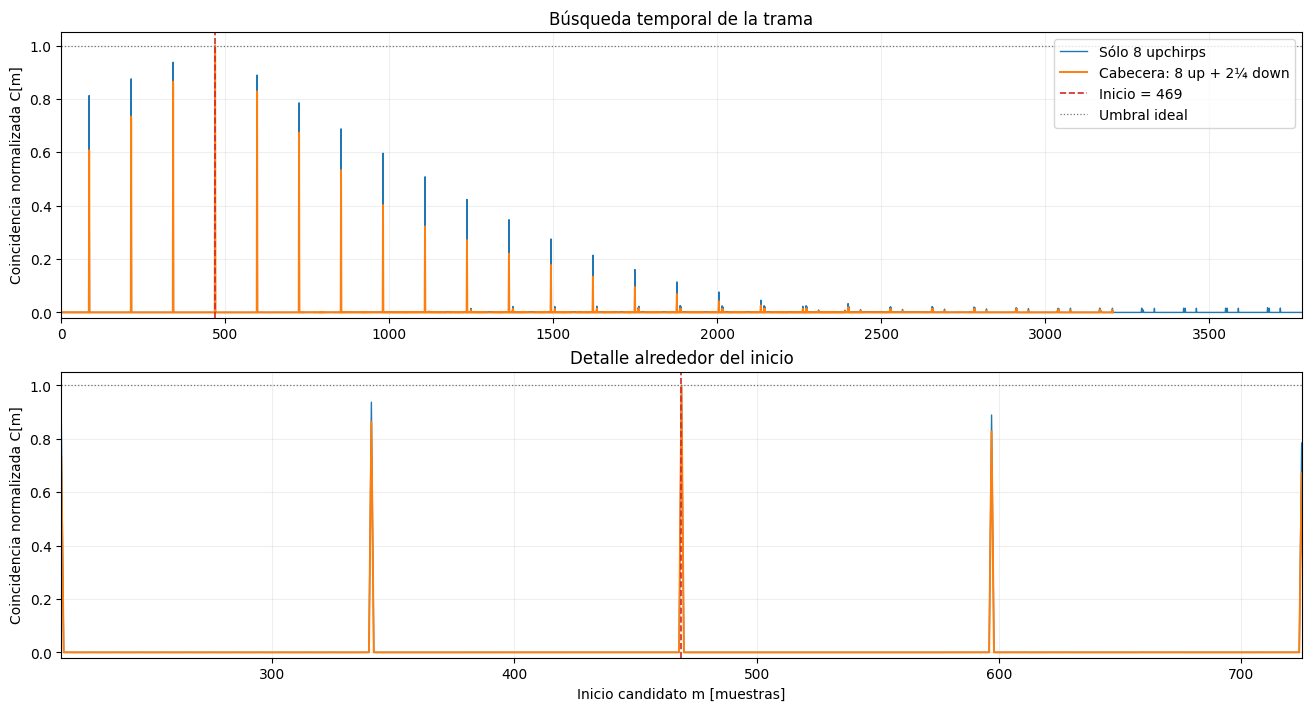

In [26]:
# Comparamos las plantillas y ampliamos el pico para ver cuál identifica el inicio.
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharey=True, constrained_layout=True)
for ax in axes:
    ax.plot(np.arange(len(puntajes_preambulo)), puntajes_preambulo,
            lw=1, color='tab:blue', label='Sólo 8 upchirps')
    ax.plot(np.arange(len(puntajes_cabecera)), puntajes_cabecera,
            lw=1.4, color='tab:orange', label='Cabecera: 8 up + 2¼ down')
    ax.axvline(inicio_detectado, color='tab:red', ls='--', lw=1.2,
               label=f'Inicio = {inicio_detectado}')
    ax.axhline(umbral_ideal, color='0.45', ls=':', lw=0.9, label='Umbral ideal')
    ax.set(ylabel='Coincidencia normalizada C[m]', ylim=(-0.02, 1.05))
    ax.grid(True, alpha=0.2)

axes[0].set(title='Búsqueda temporal de la trama', xlim=(0, len(puntajes_preambulo) - 1))
axes[0].legend(loc='upper right')
axes[1].set(xlabel='Inicio candidato m [muestras]',
            xlim=(max(0, inicio_detectado - N), inicio_detectado + N),
            title='Detalle alrededor del inicio')
plt.show()


La cabecera completa permite distinguir el inicio entre los picos del preámbulo repetido. En la fórmula usada en clase, el upchirp repite su mitad y aparecen picos separados por `N/2`; cada símbolo sigue teniendo `N` muestras.


### 3.2. Leer los 10 bytes del payload sin ruido

Avanzamos la longitud de la cabecera desde el inicio detectado y tomamos **10 bloques consecutivos de `N` muestras**. Aplicamos el helper de dechirp + FFT a cada uno y reunimos los bytes para recuperar `hola mundo`.

Si falta cualquier parte del payload, devolvemos `None`; no evaluamos un mensaje parcial como si estuviera completo.


In [27]:
# Conservamos el helper de demodulación: lo aplicamos una vez por carácter.
def leer_payload(bloque, inicio):
    if inicio is None:
        return None
    inicio_dato = inicio + len(cabecera_conocida)
    payload = bloque[inicio_dato:inicio_dato + longitud_payload]
    if len(payload) != longitud_payload:
        return None
    simbolos_recibidos = payload.reshape(cantidad_caracteres, N)
    return bytes(demodular_simbolo(simbolo)[0] for simbolo in simbolos_recibidos)


payload_recuperado = leer_payload(bloque_recibido, inicio_detectado)
if payload_recuperado is None:
    raise ValueError('Falta la cabecera detectada o el payload completo')
mensaje_recuperado = payload_recuperado.decode('ascii')
bits_recuperados = [f'{valor:08b}' for valor in payload_recuperado]
print(f'Mensaje transmitido: {mensaje!r}')
print(f'Mensaje recuperado:  {mensaje_recuperado!r}')
print(f'Bytes recuperados: {list(payload_recuperado)}')
assert payload_recuperado == payload_transmitido
assert mensaje_recuperado == mensaje and bits_recuperados == bits_payload


Mensaje transmitido: 'hola mundo'
Mensaje recuperado:  'hola mundo'
Bytes recuperados: [104, 111, 108, 97, 32, 109, 117, 110, 100, 111]


### 3.3. Repetir con ruido

Sumamos ruido gaussiano blanco complejo a **todo** el bloque: $r[n]=x[n]+w[n]$. La SNR usa la potencia de la trama activa, sin los ceros. Repetimos la correlación con un umbral manual (`0.01`), porque el puntaje ya no será 1.

*Nota:* dejamos la detección por energía y la calibración de falsas alarmas para otra etapa.


In [28]:
# El umbral es manual: usar el mismo valor no garantiza igual tasa de falsas alarmas.
umbral_ruido = 0.01
potencia_trama = np.mean(np.abs(trama_transmitida) ** 2)


def detectar_payload(bloque, umbral, plantilla=cabecera_conocida,
                     correlador=puntajes_correlacion, decodificar=True):
    """Busca el inicio usando la plantilla elegida y luego lee el payload."""
    puntajes = correlador(bloque, plantilla)
    # Ambas plantillas buscan exactamente los mismos inicios candidatos.
    cantidad_inicios = len(bloque) - len(cabecera_conocida) + 1
    puntajes = puntajes[:cantidad_inicios]
    candidato = int(np.argmax(puntajes))
    inicio = candidato if puntajes[candidato] > umbral else None
    # El dato siempre empieza después de la cabecera completa de la trama,
    # incluso cuando para detectar sólo usamos los 8 upchirps.
    dato = leer_payload(bloque, inicio) if decodificar else None
    return inicio, dato, puntajes


SNR: 10 dB | Cmáx: 0.9085 | Inicio: 469 (real: 469) | Mensaje: 'hola mundo' | Paquete correcto: True


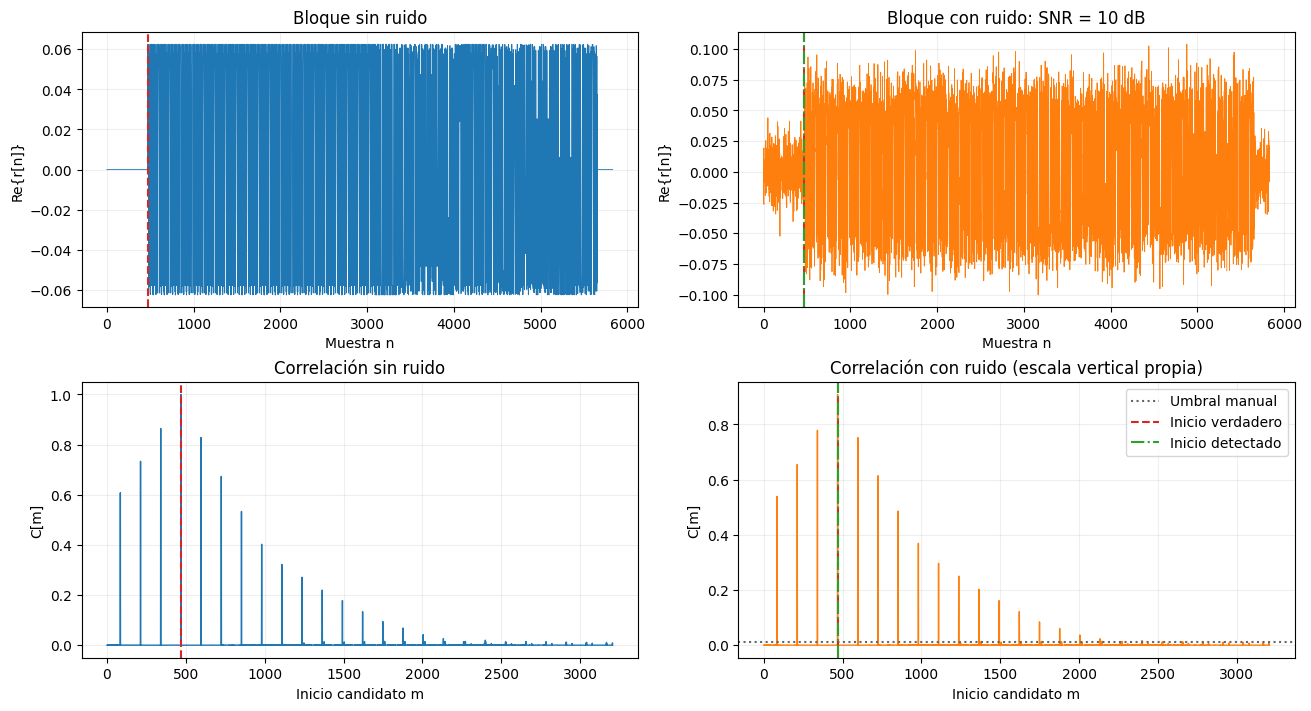

In [71]:
# Sumamos ruido al bloque y comparamos el inicio y el dato con el caso ideal.
snr_ejemplo_db = 10  # volver a ejecutar con otra SNR para comparar
generador_ruido = np.random.default_rng(2026)
potencia_ruido, sigma = parametros_ruido_desde_snr(snr_ejemplo_db, potencia_trama)
bloque_con_ruido, ruido = agregar_ruido_awgn(bloque_recibido, sigma, generador_ruido)

inicio_con_ruido, payload_con_ruido, puntajes_con_ruido = detectar_payload(
    bloque_con_ruido, umbral_ruido)
paquete_correcto = (inicio_con_ruido == inicio_verdadero and payload_con_ruido == payload_transmitido)

mensaje_con_ruido = (payload_con_ruido.decode('ascii', errors='replace')
                    if payload_con_ruido is not None else None)
# La sustitución de caracteres sólo sirve para mostrar el texto; comparamos los bytes originales.
print(f'SNR: {snr_ejemplo_db} dB | Cmáx: {puntajes_con_ruido.max():.4f}'
      f' | Inicio: {inicio_con_ruido} (real: {inicio_verdadero})'
      f' | Mensaje: {mensaje_con_ruido!r} | Paquete correcto: {paquete_correcto}')

fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
axes[0, 0].plot(bloque_recibido.real, lw=0.6)
axes[0, 0].set(title='Bloque sin ruido', ylabel='Re{r[n]}', xlabel='Muestra n')
axes[0, 1].plot(bloque_con_ruido.real, lw=0.6, color='tab:orange')
axes[0, 1].set(title=f'Bloque con ruido: SNR = {snr_ejemplo_db} dB',
               ylabel='Re{r[n]}', xlabel='Muestra n')
axes[1, 0].plot(puntajes_cabecera, lw=1)
axes[1, 0].set(title='Correlación sin ruido', ylabel='C[m]', xlabel='Inicio candidato m')
axes[1, 1].plot(puntajes_con_ruido, lw=1, color='tab:orange')
axes[1, 1].axhline(umbral_ruido, color='0.4', ls=':', label='Umbral manual')
axes[1, 1].set(title='Correlación con ruido (escala vertical propia)',
               ylabel='C[m]', xlabel='Inicio candidato m')
for ax in axes.flat:
    ax.axvline(inicio_verdadero, color='tab:red', ls='--', label='Inicio verdadero')
    ax.grid(True, alpha=0.2)
if inicio_con_ruido is not None:
    for ax in axes[:, 1]:
        ax.axvline(inicio_con_ruido, color='tab:green', ls='-.', label='Inicio detectado')
axes[1, 1].legend()
plt.show()


### 3.4. PER de detección y sincronización frente a SNR

Para cada SNR transmitimos `paquetes_por_snr` tramas con distintos inicios y ruidos. En este ejercicio la PER mide únicamente los fallos de detección y sincronización del payload. Un paquete se considera correcto cuando se declara la trama y se ubica su inicio exacto, aunque el payload recuperado contenga bytes o bits incorrectos.

| Causa | Condición | Cómo se cuenta |
|---|---|---|
| No se detecta | No hay un pico que supere el umbral | Un paquete fallido |
| Inicio incorrecto | Se declara trama, pero el inicio estimado difiere del verdadero | Un paquete fallido |

Los `if / elif` hacen que las dos causas sean **excluyentes**. El denominador es el total de paquetes transmitidos:

$$\mathrm{PER}=\frac{N_{\mathrm{no\ detectados}}+N_{\mathrm{inicio\ incorrecto}}}{K}.$$

Exigimos inicio exacto, con tolerancia de cero muestras. La simulación conoce el inicio verdadero para evaluar el resultado; el detector no recibe esa respuesta. Los errores en el contenido del payload no intervienen en esta PER. Las falsas alarmas requieren bloques sin trama y se miden aparte.

**Comparamos dos detectores:** **8 upchirps + 2¼ downchirps** y **sólo 8 upchirps**. La trama conserva los downchirps y el payload sigue después de la cabecera completa. Ambos detectores reciben las mismas realizaciones de ruido, usan el mismo rango de inicios candidatos y el umbral manual `0.01`. Un umbral común no garantiza igual probabilidad de falsa alarma; esa calibración corresponde al análisis de clase 4b.

**Canales comparados.** Flat: `h = [1]`. Selectivo: `h = [sqrt(0.8), sqrt(0.2)]`, el mismo FIR de clase 3, con un camino directo y un eco de una muestra. Ambos tienen energia impulsional unitaria. Filtramos la trama completa y conservamos la cola del FIR. El inicio verdadero corresponde al primer camino (retardo cero).

Sumamos AWGN despues del canal. La SNR se refiere a la potencia de la trama transmitida activa, sin margenes de ceros, igual que en clase 3; no renormalizamos la salida de cada canal. La potencia recibida puede variar por interferencia entre caminos. Usamos los mismos inicios y realizaciones de ruido para las cuatro combinaciones. Las plantillas del receptor siguen siendo las originales, sin compensacion ni ecualizacion del canal.

**Puntos de SNR editables.** `snrs_db` es un array explicito con valores de -18 a -5 dB. Podes agregar, quitar o modificar sus elementos. `paquetes_por_snr` determina los ensayos por punto y canal. Hay un panel por canal, con dos curvas de detectores en cada uno. Los graficos usan directamente ese array.

La correlacion paso a paso se conserva; en PER usamos la variante rapida y omitimos la decodificacion del payload. Agregar el segundo canal duplica la cantidad de correlaciones respecto del barrido con un solo canal.


In [ ]:
# Esta variante rápida se usa sólo en las repeticiones de PER.
def puntajes_correlacion_per(bloque, plantilla):
    """El mismo puntaje, calculado sin el bucle de Python por ventana."""
    L = len(plantilla)
    if len(bloque) < L:
        raise ValueError('El bloque debe contener al menos una plantilla completa')
    energia_plantilla = np.vdot(plantilla, plantilla).real
    # np.correlate conjuga la plantilla, igual que np.vdot en cada ventana.
    coincidencias = np.correlate(bloque, plantilla, mode='valid')
    energia_acumulada = np.r_[0.0, np.cumsum(np.abs(bloque) ** 2)]
    energias_ventana = energia_acumulada[L:] - energia_acumulada[:-L]
    puntajes = np.zeros(len(coincidencias))
    np.divide(np.abs(coincidencias) ** 2, energia_plantilla * energias_ventana,
              out=puntajes, where=energias_ventana > 0)
    return puntajes


# Comprobamos la equivalencia antes de usarla en la simulación.
for plantilla in (preambulo, cabecera_conocida):
    np.testing.assert_allclose(puntajes_correlacion_per(bloque_recibido, plantilla),
                               puntajes_correlacion(bloque_recibido, plantilla),
                               atol=1e-12, rtol=1e-12)

# Puntos del barrido (en dB).
snrs_db = np.array([-18, -16, -14, -12, -10, -9], dtype=float)
paquetes_por_snr = 50000
generador_per = np.random.default_rng(2027)
plantillas_per = {
    'Cabecera completa': cabecera_conocida,
    'Solo 8 upchirps': preambulo,
}
# Mismo FIR de clase 3: camino directo y eco de una muestra.
canales_per = {
    'Flat': np.array([1.0]),
    'Selectivo': np.array([np.sqrt(0.8), np.sqrt(0.2)]),
}
for h_canal in canales_per.values():
    np.testing.assert_allclose(np.sum(np.abs(h_canal)**2), 1.0)

# Convolucion completa: conservamos la cola del FIR y un largo comun.
longitud_cola = max(len(h) for h in canales_per.values()) - 1
tramas_canal = {
    canal: np.pad(np.convolve(trama_transmitida, h), (0, longitud_cola - len(h) + 1))
    for canal, h in canales_per.items()
}
combinaciones_per = [(canal, detector) for canal in canales_per for detector in plantillas_per]
resultados_per = {clave: [] for clave in combinaciones_per}
conteos_causas_per = {clave: [] for clave in combinaciones_per}

print(' SNR  Canal      Detector            No detecta  Inicio mal  Errores/K       PER', flush=True)
for snr_db in snrs_db:
    # SNR referida a la potencia TX activa, igual que en clase 3.
    _, sigma_per = parametros_ruido_desde_snr(snr_db, potencia_trama)
    conteos = {clave: np.zeros(2, dtype=int) for clave in combinaciones_per}

    for _ in range(paquetes_por_snr):
        inicio_real = int(2 * generador_per.integers(0, N) + 1)
        # Mismos inicio y ruido para ambos canales y ambos detectores.
        longitud_bloque = len(trama_transmitida) + longitud_cola + 2 * N
        _, ruido_per = agregar_ruido_awgn(np.zeros(longitud_bloque, dtype=complex),
                                         sigma_per, generador_per)
        for canal, trama_canal in tramas_canal.items():
            bloque_limpio = np.pad(trama_canal, (inicio_real, 2 * N - inicio_real))
            recibido = bloque_limpio + ruido_per
            for detector, plantilla in plantillas_per.items():
                inicio_estimado, _, _ = detectar_payload(
                    recibido, umbral_ruido, plantilla,
                    correlador=puntajes_correlacion_per, decodificar=False)
                clave = (canal, detector)
                # Solo deteccion e inicio: el contenido del payload no se evalua.
                if inicio_estimado is None:
                    conteos[clave][0] += 1
                elif inicio_estimado != inicio_real:
                    conteos[clave][1] += 1

    for canal, detector in combinaciones_per:
        clave = (canal, detector)
        no_detectados, inicios_erroneos = conteos[clave]
        errores = int(conteos[clave].sum())
        per = errores / paquetes_por_snr
        resultados_per[clave].append(per)
        conteos_causas_per[clave].append(conteos[clave].copy())
        assert 0 <= per <= 1
        print(f'{snr_db:4g}  {canal:<10} {detector:<18} {no_detectados:10d} {inicios_erroneos:11d}'
              f' {errores:5d}/{paquetes_por_snr:<4d} {per:9.2e}', flush=True)

resultados_per = {clave: np.asarray(valores) for clave, valores in resultados_per.items()}
conteos_causas_per = {clave: np.asarray(valores) for clave, valores in conteos_causas_per.items()}
for clave in combinaciones_per:
    np.testing.assert_allclose(
        conteos_causas_per[clave].sum(axis=1) / paquetes_por_snr, resultados_per[clave])


 SNR  Canal      Detector            No detecta  Inicio mal  Errores/K       PER
 -18  Flat       Cabecera completa        1366        2393  3759/50000  7.52e-02
 -18  Flat       Solo 8 upchirps          2011        8243 10254/50000  2.05e-01
 -18  Selectivo  Cabecera completa        8440        3064 11504/50000  2.30e-01
 -18  Selectivo  Solo 8 upchirps          9361        8788 18149/50000  3.63e-01
 -16  Flat       Cabecera completa           0         705   705/50000  1.41e-02
 -16  Flat       Solo 8 upchirps             4        4180  4184/50000  8.37e-02
 -16  Selectivo  Cabecera completa          60        1437  1497/50000  2.99e-02
 -16  Selectivo  Solo 8 upchirps           144        6149  6293/50000  1.26e-01
 -14  Flat       Cabecera completa           0          92    92/50000  1.84e-03
 -14  Flat       Solo 8 upchirps             0        1446  1446/50000  2.89e-02
 -14  Selectivo  Cabecera completa           0         291   291/50000  5.82e-03
 -14  Selectivo  Solo 8 upch

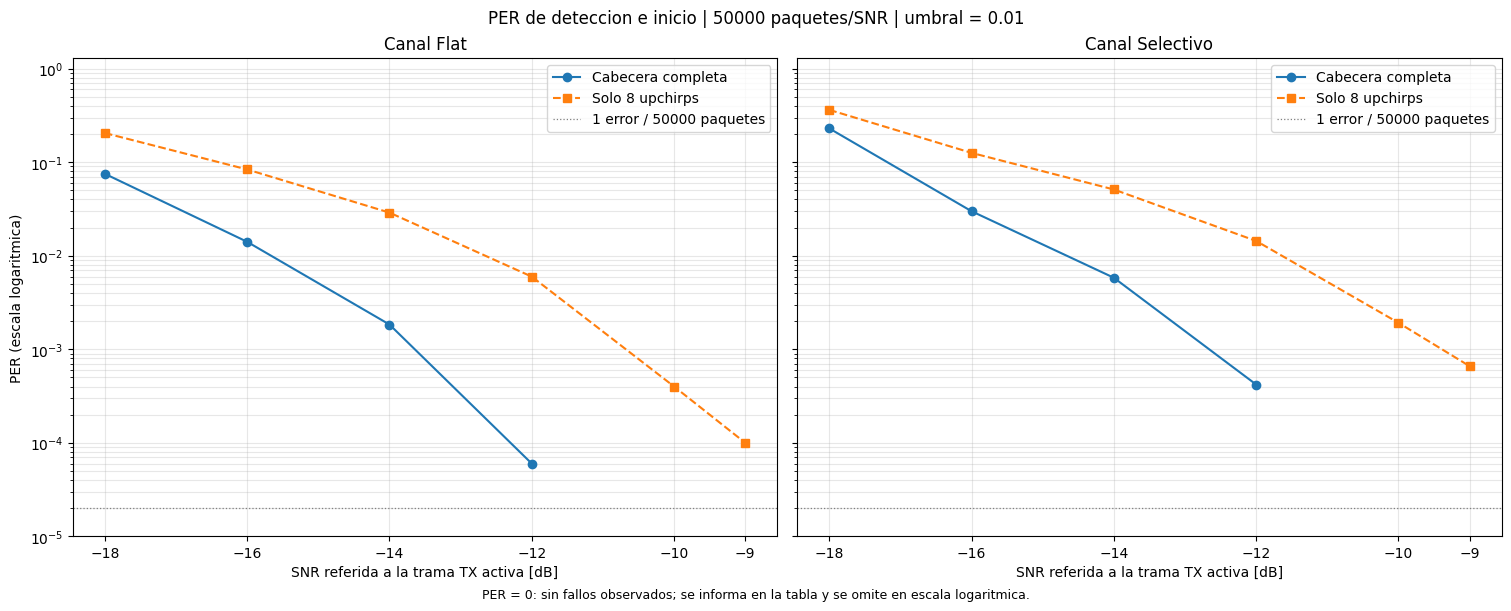

In [33]:
# Un panel por canal; dos curvas de detectores en cada panel.
fig, axes = plt.subplots(1, len(canales_per), figsize=(15, 6), sharey=True,
                         squeeze=False, constrained_layout=True)
estilos_detectores = dict(zip(plantillas_per, ('o-', 's--')))
for ax, canal in zip(axes[0], canales_per):
    for detector in plantillas_per:
        per = resultados_per[(canal, detector)]
        ax.semilogy(snrs_db, np.where(per > 0, per, np.nan), estilos_detectores[detector],
                    lw=1.5, label=detector)
    ax.axhline(1 / paquetes_por_snr, color='0.5', ls=':', lw=0.9,
               label=f'1 error / {paquetes_por_snr} paquetes')
    ax.set(xlabel='SNR referida a la trama TX activa [dB]',
           title=f'Canal {canal}', ylim=(0.5 / paquetes_por_snr, 1.3))
    ax.set_xticks(snrs_db)
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
axes[0, 0].set_ylabel('PER (escala logaritmica)')
fig.suptitle(f'PER de deteccion e inicio | {paquetes_por_snr} paquetes/SNR | umbral = {umbral_ruido}')
fig.supxlabel('PER = 0: sin fallos observados; se informa en la tabla y se omite en escala logaritmica.',
              fontsize=9)
plt.show()


**Cómo leer las curvas.** Un punto en $10^{-2}$ significa que aproximadamente el 1 % de los paquetes no se detectó o tuvo un inicio estimado incorrecto. Un payload con errores de contenido y con inicio correcto no incrementa esta PER. Las cuatro curvas de canal y detector no se suman entre sí.

Una PER de cero significa cero fallos de detección o inicio observados, no una probabilidad real necesariamente nula. Un único fallo representa `1 / paquetes_por_snr`. Los ceros se conservan en la tabla y se omiten en la escala logarítmica.

Esta métrica no es BER ni mide la integridad del mensaje recuperado. Los resultados corresponden al payload transmitido y a los canales flat y selectivo con AWGN y SF=8.


### 3.5. Causas de fallo de detección y sincronización

Cada barra apila las **dos causas excluyentes** del contador: no se declara trama e inicio incorrecto. Su altura total es la PER del receptor para esa SNR. El eje vertical es lineal para mostrar ceros y sumar las partes; los colores tienen el mismo significado en los cuatro paneles.

Los errores de contenido del payload quedan fuera del contador y de estas barras. Comparamos canal flat y selectivo con AWGN y umbral manual, sin desajustes de frecuencia o reloj.


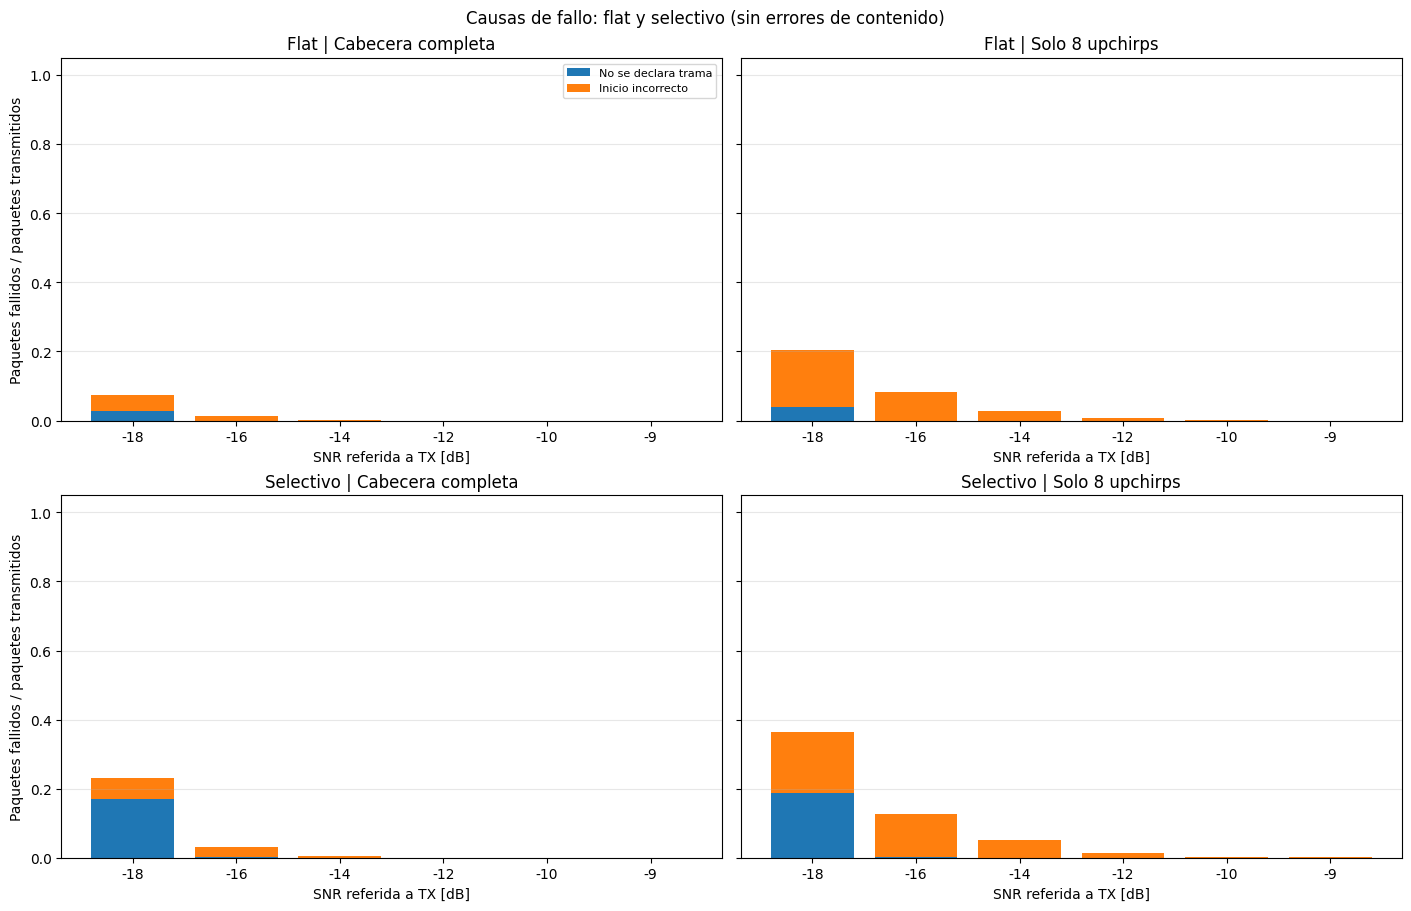

In [34]:
# Filas: canales. Columnas: detectores. La altura total es la PER.
fig, axes = plt.subplots(len(canales_per), len(plantillas_per), figsize=(14, 9),
                         sharey=True, squeeze=False, constrained_layout=True)
etiquetas_causas = ('No se declara trama', 'Inicio incorrecto')
colores_causas = ('tab:blue', 'tab:orange')
posiciones = np.arange(len(snrs_db))
for fila, canal in enumerate(canales_per):
    for columna, detector in enumerate(plantillas_per):
        ax = axes[fila, columna]
        fracciones = conteos_causas_per[(canal, detector)] / paquetes_por_snr
        base = np.zeros(len(snrs_db))
        for j, (etiqueta, color) in enumerate(zip(etiquetas_causas, colores_causas)):
            ax.bar(posiciones, fracciones[:, j], bottom=base, color=color, label=etiqueta)
            base += fracciones[:, j]
        ax.set(title=f'{canal} | {detector}', xlabel='SNR referida a TX [dB]', ylim=(0, 1.05))
        ax.set_xticks(posiciones, [f'{snr:g}' for snr in snrs_db])
        ax.grid(True, axis='y', alpha=0.3)
        if columna == 0:
            ax.set_ylabel('Paquetes fallidos / paquetes transmitidos')
axes[0, 0].legend(loc='upper right', fontsize=8)
fig.suptitle('Causas de fallo: flat y selectivo (sin errores de contenido)')
plt.show()


### 3.6 Deteccion con un solo upchirp 

El receptor guarda solamente un upchirp cero de $N$ muestras. Reutilizamos la correlación normalizada del punto 3.1, ahora con una plantilla de un solo upchirp. Una coincidencia aislada no confirma el preámbulo: exigimos ocho consecutivas separadas exactamente por $N$ muestras (un Ts).

Para cada comienzo candidato $\ell$, contamos la coincidencia actual más las anteriores en $\ell-N$, $\ell-2N$, etc. Si falla el umbral, esa cadena se reinicia en cero. En código, `contador[ell]` usa `contador[ell - N]`, no el de la muestra vecina. Así se buscan todos los alineamientos posibles sin contar varias veces un mismo chirp.

Declaramos la primera cadena que alcanza ocho coincidencias. Si la octava ventana comienza en $\ell$, el comienzo estimado del preámbulo es $\ell-7N$ y la última muestra necesaria para confirmarlo es $\ell+N-1$. Por eso se confirma después de observar 8 Ts de señal, aunque se informe el comienzo anterior.

Esta alternativa no usa los downchirps ni el payload para decidir. Requiere conocer SF y B y no considera errores de frecuencia o de reloj. Una repetición de ocho upchirps en cualquier otra transmisión también cumpliría la condición: detectamos un preámbulo candidato, no autenticamos una trama. El umbral se debe ajustar al ruido; exigir ocho aciertos sin fallas es una primera estrategia estricta.


In [47]:
def detectar_preambulo_upchirp(recibida, plantilla_up, umbral=0.8, cantidad_upchirps=8):
    """Detecta la primera cadena de coincidencias separadas por un símbolo."""
    if not np.isscalar(umbral) or not np.isrealobj(umbral) or not 0 < umbral <= 1:
        raise ValueError("El umbral debe estar entre 0 (excluido) y 1.")
    if not isinstance(cantidad_upchirps, (int, np.integer)) or cantidad_upchirps < 1:
        raise ValueError("cantidad_upchirps debe ser un entero positivo.")

    coincidencia = puntajes_correlacion(recibida, plantilla_up) # Se usa el calculo de correlacion del punto 3.1
    N = len(plantilla_up)
    contador = np.zeros(coincidencia.size, dtype=int)   # Cada posición guarda cuántos upchirps consecutivos llevamos detectados en la cadena que termina allí (inicializamos en cero)   

    for ell, valor in enumerate(coincidencia):
        if valor >= umbral:                                         # Si el valor de coincidencia supera el umbral,
            anterior = contador[ell - N] if ell >= N else 0         # se incrementa el contador en 1,
            contador[ell] = min(anterior + 1, cantidad_upchirps)    # pero no puede superar la cantidad de upchirps deseada.
        # Si no supera el umbral, contador[ell] queda en cero.

    candidatos = np.flatnonzero(contador >= cantidad_upchirps)      # Busca si alguna cadena llegó a 8 
    detectado = candidatos.size > 0

    ultima_ventana = int(candidatos[0]) if detectado else None      # Si se detectó, toma la primera posición donde se cumple la condición (Esa posición es el inicio del octavo upchirp, no el del primero)
    inicio = ultima_ventana - (cantidad_upchirps - 1) * N if detectado else None    # Calcula el inicio del primer upchirp de la cadena detectada
    
    posiciones = inicio + np.arange(cantidad_upchirps) * N if detectado else np.array([], dtype=int)    # Calcula las posiciones de los 8 upchirps detectados en la cadena

    return {
        "detectado": bool(detectado),
        "inicio_preambulo": inicio,
        "muestra_confirmacion": ultima_ventana + N - 1 if detectado else None,
        "posiciones_coincidencias": posiciones,
        "coincidencias_aceptadas": coincidencia[posiciones],
        "coincidencia": coincidencia,
        "contador": contador,
        "umbral": umbral,
        "cantidad_upchirps": cantidad_upchirps,
    }

### Correlación y evolución del contador

Arriba se muestra la correlación con el único upchirp para las capturas ideal y ruidosa. Los ocho puntos rojos son las coincidencias seleccionadas en el caso ruidoso. Abajo mostramos el contador a lo largo del alineamiento detectado: se incrementa una vez por símbolo, no por cada muestra de la captura. La línea de confirmación marca el momento en que ya llegaron las ocho ventanas completas; no es el comienzo del preámbulo.

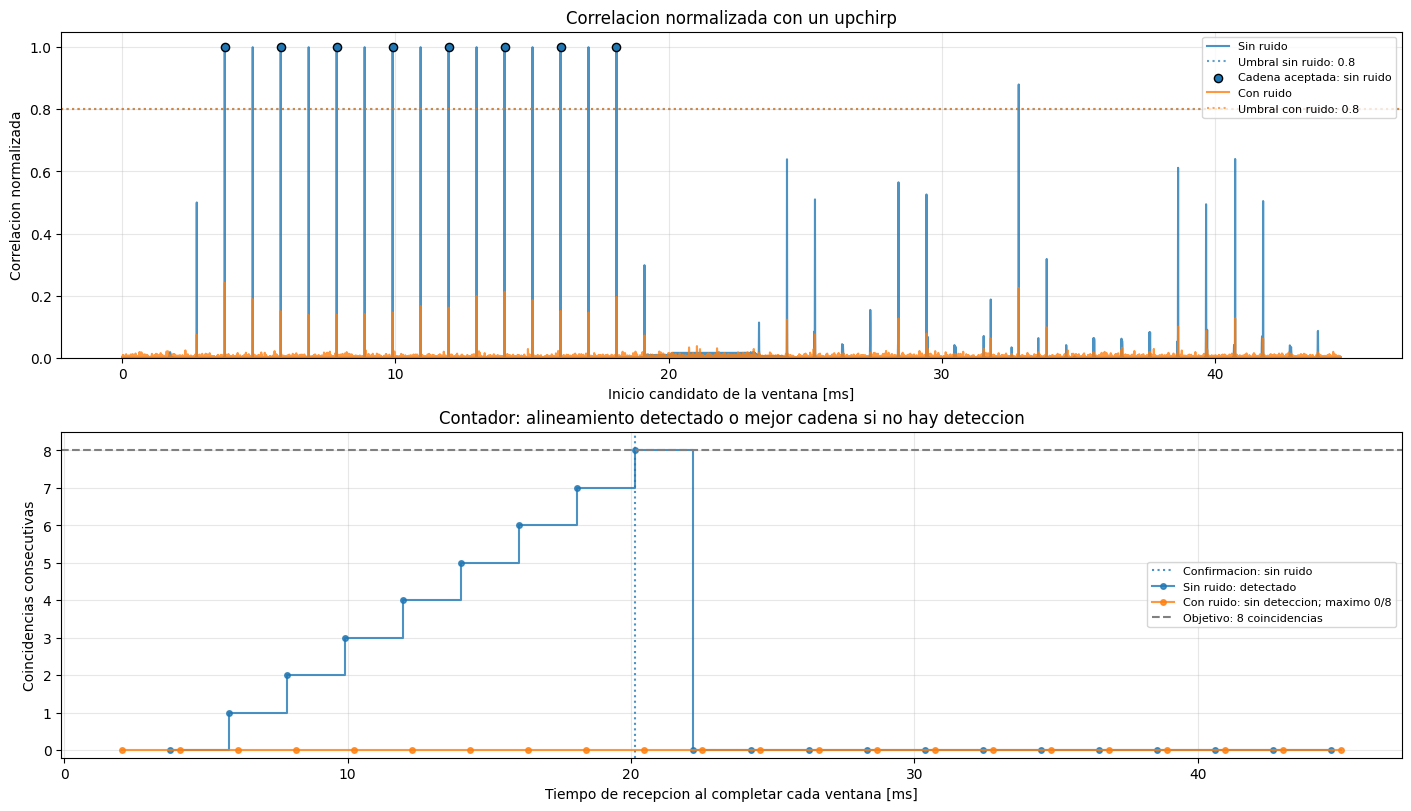

In [73]:
# Solo visualizacion: reutilizamos los resultados, sin modificar el detector.
fig_un_up, ejes_un_up = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
casos_grafico = (
    ('Sin ruido', resultado_up_ideal, 'tab:blue'),
    ('Con ruido', resultado_up_ruido, 'tab:orange'),
)

for nombre, resultado, color in casos_grafico:
    coincidencias = np.asarray(resultado['coincidencia'])
    contador_grafico = np.asarray(resultado['contador'])
    muestras_up = len(plantilla_un_up)
    objetivo = resultado['cantidad_upchirps']
    tiempos = np.arange(coincidencias.size) / B * 1000
    ejes_un_up[0].plot(tiempos, coincidencias, color=color, alpha=0.8, label=nombre)
    ejes_un_up[0].axhline(resultado['umbral'], color=color, ls=':', alpha=0.7,
                          label=f'Umbral {nombre.lower()}: {resultado["umbral"]:g}')

    if resultado['detectado']:
        posiciones = np.asarray(resultado['posiciones_coincidencias'], dtype=int)
        ejes_un_up[0].scatter(posiciones / B * 1000, coincidencias[posiciones],
                              color=color, edgecolors='black', s=35, zorder=5,
                              label=f'Cadena aceptada: {nombre.lower()}')
        ancla = int(resultado['inicio_preambulo'])
        estado = 'detectado'
        ejes_un_up[1].axvline(resultado['muestra_confirmacion'] / B * 1000,
                              color=color, ls=':', alpha=0.8,
                              label=f'Confirmacion: {nombre.lower()}')
    else:
        # Mostrar el alineamiento que alcanzo el mayor contador, aunque no llego a ocho.
        ancla = int(np.argmax(contador_grafico))
        estado = f'sin deteccion; maximo {int(contador_grafico.max())}/{objetivo}'

    # Recorremos un solo alineamiento, separado por N muestras: permite ver reinicios.
    posiciones_contador = np.arange(ancla % muestras_up, contador_grafico.size, muestras_up)
    fin_ventanas = posiciones_contador + muestras_up - 1
    ejes_un_up[1].step(fin_ventanas / B * 1000, contador_grafico[posiciones_contador],
                       where='post', marker='o', ms=4, color=color, alpha=0.8,
                       label=f'{nombre}: {estado}')

objetivo_grafico = max(r['cantidad_upchirps'] for _, r, _ in casos_grafico)
ejes_un_up[0].set(title='Correlacion normalizada con un upchirp',
                  xlabel='Inicio candidato de la ventana [ms]', ylabel='Correlacion normalizada',
                  ylim=(0, 1.05))
ejes_un_up[1].axhline(objetivo_grafico, color='gray', ls='--',
                      label=f'Objetivo: {objetivo_grafico} coincidencias')
ejes_un_up[1].set(title='Contador: alineamiento detectado o mejor cadena si no hay deteccion',
                  xlabel='Tiempo de recepcion al completar cada ventana [ms]',
                  ylabel='Coincidencias consecutivas', ylim=(-0.2, objetivo_grafico + 0.5))
ejes_un_up[1].set_yticks(np.arange(objetivo_grafico + 1))
for eje in ejes_un_up:
    eje.grid(True, alpha=0.3)
    eje.legend(fontsize=8)
plt.show()


## 4. Detección en frecuencia
Buscamos solamente el preámbulo de 8 upchirps. Para cada comienzo candidato $\ell$ evaluamos ocho ventanas consecutivas de $N=2^{SF}$ muestras. Desplazamos el comienzo candidato una muestra a la vez, porque el receptor no sabe dónde empieza el preámbulo.

En cada ventana hacemos el dechirp y aplicamos la FFT. Si la ventana está alineada con un upchirp cero, el resultado ideal es constante y su FFT concentra la energía en el bin 0.

Para cada ventana calculamos:

$$Q=\frac{|D[0]|^2}{\sum_p |D[p]|^2}.$$

Una ventana perfecta da 1 y una ventana sin energía da 0. Para exigir que **las ocho** ventanas superen el umbral, usamos como puntuación de la secuencia el mínimo de sus ocho valores $Q$. El detector selecciona el candidato con el mayor de esos mínimos y declara detección si ese valor es al menos el umbral.

Se conoce SF y B; el ejemplo utiliza un canal plano, sin errores de frecuencia ni de reloj. La puntuación basada en el bin cero no corrige esos desplazamientos.

La funcion `validar_concentracion_bin_cero` reúne las comprobaciones de entrada.

In [54]:
def validar_concentracion_bin_cero(recibida, referencia, tamano_lote):
    """Valida captura, referencia y tamaño de lote para el cálculo."""
    if recibida.ndim != 1 or referencia.ndim != 1 or referencia.size == 0:
        raise ValueError("La captura y la referencia deben ser vectores; la referencia no puede estar vacía.")
    if recibida.size < referencia.size:
        raise ValueError("La captura debe contener al menos una ventana completa.")
    if not np.all(np.isfinite(recibida)) or not np.all(np.isfinite(referencia)):
        raise ValueError("Las muestras deben ser finitas.")
    if not isinstance(tamano_lote, (int, np.integer)) or tamano_lote < 1:
        raise ValueError("El tamaño de lote debe ser un entero positivo.")
    if not np.allclose(np.abs(referencia), 1):
        raise ValueError("La referencia de dechirp debe tener módulo uno.")

La función `concentracion_bin_cero` calcula el puntaje de cada ventana usando la FFT. `detectar_preambulo_frecuencia` toma ocho valores separados por N muestras para cada inicio candidato y exige que todos alcancen el umbral. La captura se procesa por lotes para limitar el uso de memoria.

In [75]:
def concentracion_bin_cero(recibida, referencia, tamano_lote=256):
    """Puntaje espectral de cada ventana frente a un chirp de referencia."""
    recibida = np.asarray(recibida, dtype=complex)
    referencia = np.asarray(referencia, dtype=complex)
    validar_concentracion_bin_cero(recibida, referencia, tamano_lote)

    M = referencia.size                                                 # Tamaño de la ventana de análisis (dechirp).
    ventanas = np.lib.stride_tricks.sliding_window_view(recibida, M)    # Dividimos la captura en ventanas de tamaño M (avanzando de a 1 muestra).
    puntajes = np.zeros(len(ventanas))                                  # Puntaje espectral (Q) de cada ventana frente a la referencia.
    
    for inicio in range(0, len(ventanas), tamano_lote):                 # Procesamos en lotes para ahorrar memoria.

        fin = min(inicio + tamano_lote, len(ventanas))                  # Fin del lote.
        
        dechirp = ventanas[inicio:fin] * referencia                     # Aplicamos el dechirp a cada ventana.
        espectros = np.fft.fft(dechirp, axis=-1) / np.sqrt(M) # Aplicamos FFT normalizada en cada fila.
        
        energia = np.sum(np.abs(espectros) ** 2, axis=1)                # Calculamos la energia de todos los bins
        pico_cero = np.abs(espectros[:, 0]) ** 2                        # Calculamos la energia del bin cero de cada ventana

        np.divide(pico_cero, energia, out=puntajes[inicio:fin], where=energia > 0)  # Calculamos Q de cada ventana y se guarda en puntajes (sin dividir por cero)

    return np.clip(puntajes, 0, 1)      # devolvemos puntajes Q 


def detectar_preambulo_frecuencia(recibida, SF, B, umbral=0.8, tamano_lote=256):
    """Busca ocho upchirps usando dechirp y FFT, sin analizar la trama posterior."""
    if not isinstance(SF, (int, np.integer)) or SF < 2:
        raise ValueError("SF debe ser un entero mayor o igual a 2.")
    if not np.isscalar(umbral) or not np.isrealobj(umbral) or not 0 < umbral <= 1:
        raise ValueError("El umbral debe estar entre 0 (excluido) y 1.")

    recibida = np.asarray(recibida, dtype=complex)
    N = 2 ** SF
    longitud_preambulo = 8 * N
    
    if recibida.ndim != 1 or recibida.size < longitud_preambulo:
        raise ValueError("La captura debe ser un vector con al menos ocho símbolos completos.")

    up_unitario = modular_simbolo(0, k, N) * np.sqrt(N) 
    referencia_dechirp = np.conj(up_unitario)                                   # Definimos un Downchirp para hacer el dechirp.
    q_up = concentracion_bin_cero(recibida, referencia_dechirp, tamano_lote)    # Calculamos el puntaje espectral (Q) de cada ventana.

    cantidad_candidatos = recibida.size - longitud_preambulo + 1        # Aseguramos que la ultima ventana tenga al menos ocho símbolos completos.
    evidencias_up = np.stack([
        q_up[j * N:j * N + cantidad_candidatos] for j in range(8)       # Agrupamos los Q de las ocho ventanas de upchirps consecutivas (cada una de tamaño N)
    ])                                                                  # filas: cada upchirp, columnas: cada ventana de tamaño N.
    
    # El mínimo supera el umbral solo si las ocho ventanas lo superan.
    puntuacion = np.min(evidencias_up, axis=0)          # Tomamos el minimo valor de cada columna 
    indice_maximo = int(np.argmax(puntuacion))          # Buscamos el indice de la columna con el valor máximo de puntuacion
    maximo = float(puntuacion[indice_maximo])           # Buscamos el valor máximo de puntuacion
    detectado = maximo >= umbral                        # Si el máximo supera el umbral, consideramos que se detectó un preámbulo.

    return {
        "detectado": detectado,
        "inicio_preambulo": indice_maximo if detectado else None,
        "indice_maximo": indice_maximo,
        "fin_upchirps": indice_maximo + longitud_preambulo if detectado else None,
        "puntuacion_maxima": maximo,
        "puntuacion": puntuacion,
        "evidencias_up": evidencias_up,
        "longitud_preambulo": longitud_preambulo,
        "umbral": umbral,
    }

### Prueba con una trama desplazada

Reutilizamos las capturas ideal y ruidosa de la clase anterior. Para detectar, la función usa únicamente las muestras que corresponden a los ocho upchirps para cada candidato. La captura de ejemplo también contiene el resto de la trama, pero no se emplea una plantilla de downchirps. El `inicio_verdadero` se consulta solo después, para comprobar el resultado.

In [76]:
UMBRAL_FRECUENCIA = 0.8

resultado_frecuencia_ideal = detectar_preambulo_frecuencia(
    bloque_recibido, SF, B, umbral=UMBRAL_FRECUENCIA
)
resultado_frecuencia_ruido = detectar_preambulo_frecuencia(
    bloque_con_ruido, SF, B, umbral=UMBRAL_FRECUENCIA
)

print(f"Inicio real de prueba: muestra {inicio_verdadero}")
for nombre, resultado in (("Sin ruido", resultado_frecuencia_ideal),
                          ("Con ruido", resultado_frecuencia_ruido)):
    print(f"{nombre}: detectado={resultado['detectado']}; "
          f"menor concentración de los 8 upchirps={resultado['puntuacion_maxima']:.4f}; "
          f"inicio estimado={resultado['inicio_preambulo']}")

# Comprobación para esta captura ideal; no implica sincronización perfecta en general.
assert resultado_frecuencia_ideal["inicio_preambulo"] == inicio_verdadero
assert np.isclose(resultado_frecuencia_ideal["puntuacion_maxima"], 1)

Inicio real de prueba: muestra 469
Sin ruido: detectado=True; menor concentración de los 8 upchirps=1.0000; inicio estimado=469
Con ruido: detectado=True; menor concentración de los 8 upchirps=0.9036; inicio estimado=469


### Puntuación y FFT de los upchirps

En el primer gráfico se muestra, para cada inicio candidato, el menor de los ocho puntajes espectrales. La línea horizontal es el umbral; la vertical marca el inicio real solo para verificar la simulación.

En el segundo se muestran los ocho puntajes de la secuencia elegida en la captura ruidosa. En el tercero se muestra la FFT del primer upchirp de esa secuencia después del dechirp. La referencia usada para el dechirp se genera localmente en el receptor y no representa un downchirp recibido de la trama. Si no hay detección, los dos últimos gráficos quedan vacíos.

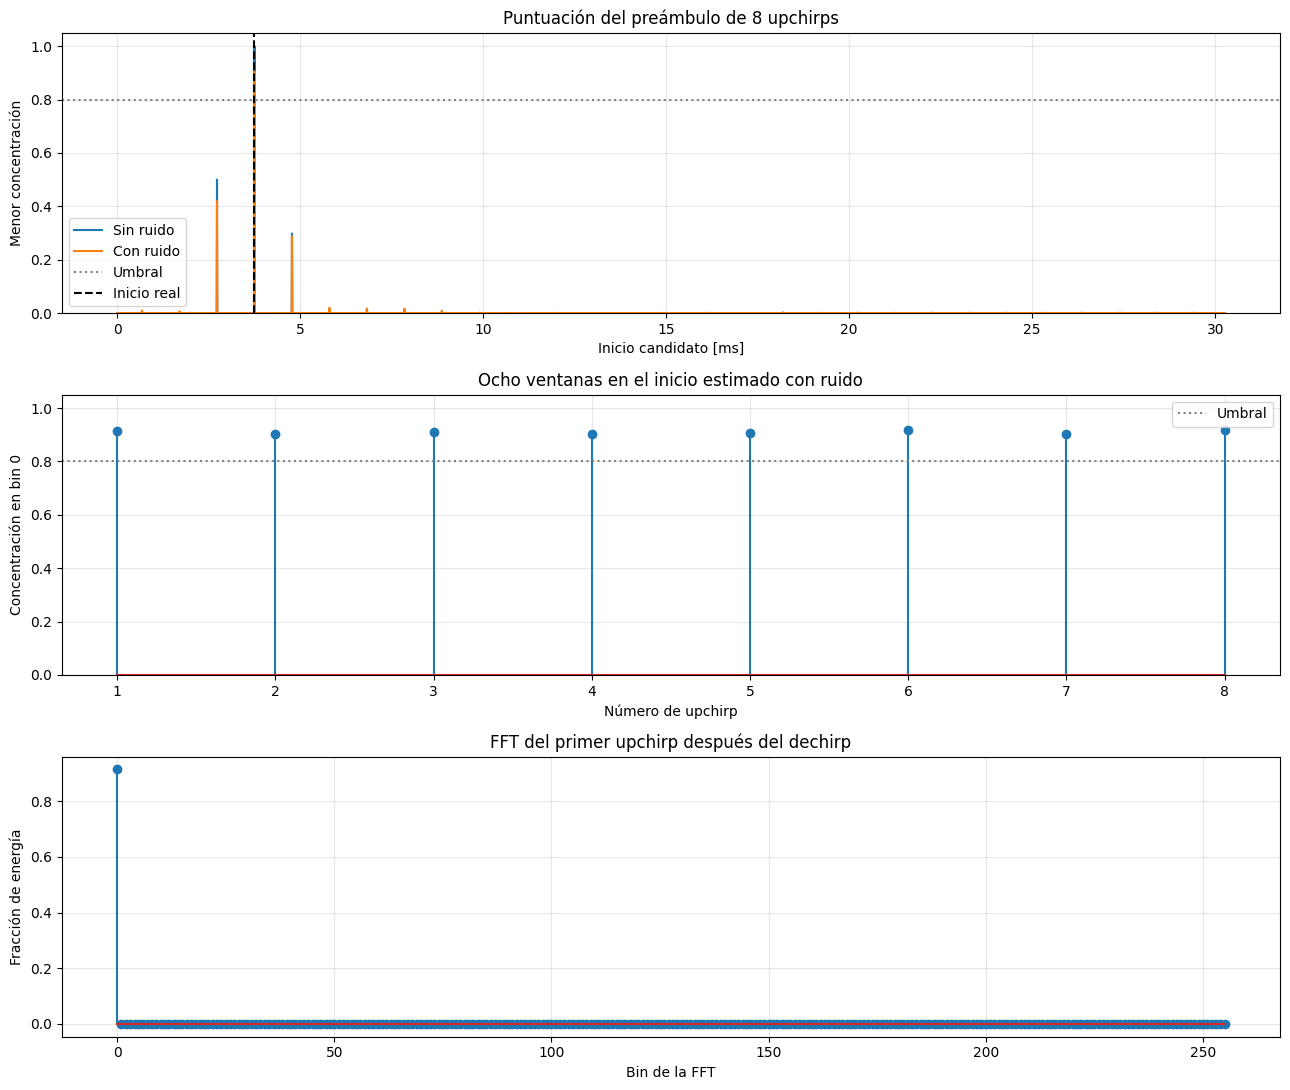

In [77]:
fig_deteccion_frecuencia, ejes_freq = plt.subplots(3, 1, figsize=(13, 11))
for nombre, resultado in (("Sin ruido", resultado_frecuencia_ideal),
                          ("Con ruido", resultado_frecuencia_ruido)):
    tiempos = np.arange(resultado["puntuacion"].size) / B * 1000
    ejes_freq[0].plot(tiempos, resultado["puntuacion"], label=nombre)
ejes_freq[0].axhline(UMBRAL_FRECUENCIA, color="gray", linestyle=":", label="Umbral")
ejes_freq[0].axvline(inicio_verdadero / B * 1000, color="black", linestyle="--", label="Inicio real")
ejes_freq[0].set(title="Puntuación del preámbulo de 8 upchirps",
                 xlabel="Inicio candidato [ms]", ylabel="Menor concentración")
ejes_freq[0].set_ylim(0, 1.05)
ejes_freq[0].legend()

if resultado_frecuencia_ruido["detectado"]:
    comienzo = resultado_frecuencia_ruido["inicio_preambulo"]
    ocho_valores = resultado_frecuencia_ruido["evidencias_up"][:, comienzo]
    ejes_freq[1].stem(np.arange(1, 9), ocho_valores)
    ejes_freq[1].axhline(UMBRAL_FRECUENCIA, color="gray", linestyle=":", label="Umbral")
    ejes_freq[1].legend()

    up_unitario = modular_simbolo(0, k, N) * np.sqrt(N)
    ventana = bloque_con_ruido[comienzo:comienzo + N]
    espectro = np.fft.fft(ventana * np.conj(up_unitario)) / np.sqrt(N)
    
    potencia = np.abs(espectro) ** 2
    if potencia.sum() > 0:
        ejes_freq[2].stem(np.arange(N), potencia / potencia.sum())
else:
    for eje in ejes_freq[1:]:
        eje.text(0.5, 0.5, "No se detectó una secuencia de ocho upchirps.",
                 transform=eje.transAxes, ha="center")

ejes_freq[1].set(title="Ocho ventanas en el inicio estimado con ruido",
                 xlabel="Número de upchirp", ylabel="Concentración en bin 0")
ejes_freq[1].set_xticks(np.arange(1, 9))
ejes_freq[1].set_ylim(0, 1.05)
ejes_freq[2].set(title="FFT del primer upchirp después del dechirp",
                 xlabel="Bin de la FFT", ylabel="Fracción de energía")
for eje in ejes_freq:
    eje.grid(True, alpha=0.3)
fig_deteccion_frecuencia.tight_layout()
plt.show()